<a href="https://colab.research.google.com/github/madhuvanthi11/4th/blob/master/DR_Progression_Preliminary_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU: True
Tesla T4


In [2]:
!pip install -q timm albumentations opencv-python-headless scikit-learn seaborn grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
!pip install -q kaggle

In [4]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [5]:
!kaggle competitions list -s aptos

ref                                                                deadline             category       reward  teamCount  userHasEntered  userRank  
-----------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  --------  
https://www.kaggle.com/competitions/aptos2019-blindness-detection  2019-09-07 23:59:00  Featured   50,000 Usd       2928            True         0  
https://www.kaggle.com/competitions/precio-aptos-medellin          2050-09-26 23:59:00  Community       Kudos         24           False         0  
https://www.kaggle.com/competitions/aptos                          2018-03-11 23:59:00  Community       Kudos         18           False         0  
https://www.kaggle.com/competitions/copy-of-2022-tzuchi-mi-2       2022-11-19 23:59:00  Community       Kudos          2           False         0  
https://www.kaggle.com/competitions/2022-tzuchi-mi                 2022-11-19 23:59:00  Community       Ku

In [6]:
!pip install -q -U kaggle

In [7]:
!kaggle competitions download -c aptos2019-blindness-detection -p /content

100% 9.51G/9.51G [07:56<00:00, 21.5MB/s]



In [8]:
!ls -lh /content/aptos2019-blindness-detection.zip

-rw-r--r-- 1 root root 9.6G Dec 18  2019 /content/aptos2019-blindness-detection.zip


In [9]:
!mkdir -p /content/aptos
!unzip -q /content/aptos2019-blindness-detection.zip -d /content/aptos

In [10]:
!find /content/aptos -maxdepth 2 -type f | head -20

/content/aptos/sample_submission.csv
/content/aptos/train_images/80dbeb0fdc75.png
/content/aptos/train_images/247ac63e5510.png
/content/aptos/train_images/3c28fd846b43.png
/content/aptos/train_images/17e6116b89b3.png
/content/aptos/train_images/b8dab47a260e.png
/content/aptos/train_images/4d9fc85a8259.png
/content/aptos/train_images/f549294e12e1.png
/content/aptos/train_images/3b0190bbe615.png
/content/aptos/train_images/50ddd7d976df.png
/content/aptos/train_images/8b568d47a1fd.png
/content/aptos/train_images/875d2ffcbf47.png
/content/aptos/train_images/7aabd768abff.png
/content/aptos/train_images/1bb0ddfe753a.png
/content/aptos/train_images/e3cd96cb094c.png
/content/aptos/train_images/c68dfa021d62.png
/content/aptos/train_images/1864d3411143.png
/content/aptos/train_images/b553e7909535.png
/content/aptos/train_images/d88c4843aec3.png
/content/aptos/train_images/28dc010a0780.png


In [11]:
import os

train_dir = "/content/aptos/train_images"

print("Number of training images:",
      len(os.listdir(train_dir)))

Number of training images: 3662


In [12]:
import pandas as pd

df = pd.read_csv("/content/aptos/train.csv")

print("Number of labelled images:", len(df))
print(df.head())

Number of labelled images: 3662
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0


In [13]:
print(df["diagnosis"].value_counts().sort_index())

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


In [14]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv("/content/aptos/train.csv")

image_dir = "/content/aptos/train_images"

print("Images:", len(os.listdir(image_dir)))
print("Labels:", len(df))

Images: 3662
Labels: 3662


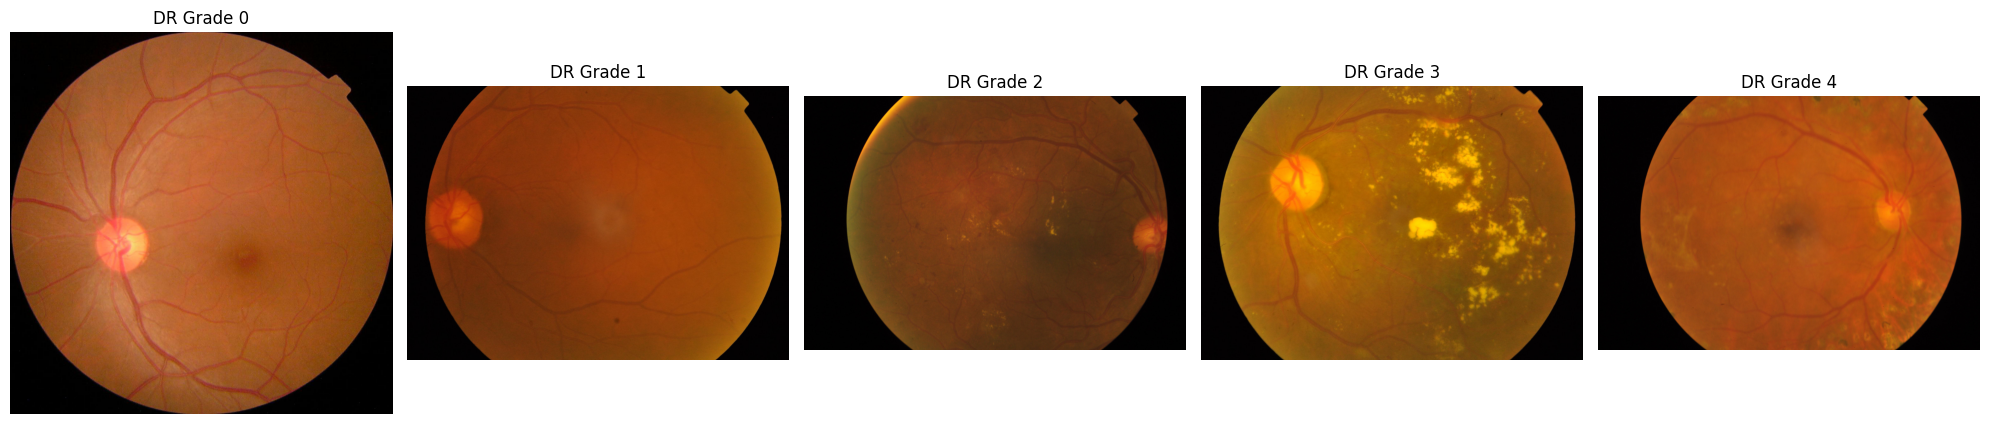

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for grade in range(5):

    row = df[df["diagnosis"] == grade].iloc[0]

    image_path = os.path.join(
        image_dir,
        row["id_code"] + ".png"
    )

    image = Image.open(image_path)

    axes[grade].imshow(image)
    axes[grade].set_title(f"DR Grade {grade}")
    axes[grade].axis("off")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["diagnosis"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 2563
Validation: 549
Testing: 550


In [17]:
print("TRAIN")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nVALIDATION")
print(val_df["diagnosis"].value_counts().sort_index())

print("\nTEST")
print(test_df["diagnosis"].value_counts().sort_index())

TRAIN
diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

VALIDATION
diagnosis
0    271
1     55
2    150
3     29
4     44
Name: count, dtype: int64

TEST
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


In [18]:
!pip install -q timm albumentations opencv-python-headless

In [19]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import timm
import albumentations as A

from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [20]:
IMG_SIZE = 224

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.HorizontalFlip(p=0.5),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.3
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.05,
        rotate_limit=15,
        p=0.3
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [21]:
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

In [22]:
class DRDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["id_code"] + ".png"
        )

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        label = int(row["diagnosis"])

        if self.transform:
            image = self.transform(
                image=image
            )["image"]

        return image, label

In [23]:
train_dataset = DRDataset(
    train_df,
    image_dir,
    train_transform
)

val_dataset = DRDataset(
    val_df,
    image_dir,
    val_transform
)

test_dataset = DRDataset(
    test_df,
    image_dir,
    val_transform
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 2563
Validation: 549
Testing: 550


In [24]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Data type:", image.dtype)

Image shape: torch.Size([3, 224, 224])
Label: 0
Data type: torch.float32


In [25]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [26]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels[:10])

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Labels: tensor([0, 0, 2, 2, 1, 2, 0, 0, 0, 2])


In [27]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using: cuda
Tesla T4


In [28]:
import timm
import torch

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

print(model)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2

In [29]:
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 5])


In [30]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.sort(train_df["diagnosis"].unique())

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

print("Class weights:")
for cls, weight in zip(classes, weights):
    print(f"Class {cls}: {weight:.3f}")

Class weights:
Class 0: 0.406
Class 1: 1.979
Class 2: 0.733
Class 3: 3.797
Class 4: 2.476


In [31]:
class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

print(class_weights)

tensor([0.4059, 1.9792, 0.7333, 3.7970, 2.4763], device='cuda:0')


In [32]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [33]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [34]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [35]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [36]:
EPOCHS = 5

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, _, _ = validate(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "/content/best_dr_model.pth"
        )

print("\nBest validation accuracy:", best_val_acc)

Epoch 1/5 | Train Loss: 1.8916 | Train Acc: 0.5533 | Val Loss: 1.7045 | Val Acc: 0.6703
Epoch 2/5 | Train Loss: 0.9661 | Train Acc: 0.7132 | Val Loss: 1.3001 | Val Acc: 0.6903
Epoch 3/5 | Train Loss: 0.7017 | Train Acc: 0.7932 | Val Loss: 1.2390 | Val Acc: 0.7031
Epoch 4/5 | Train Loss: 0.5895 | Train Acc: 0.8139 | Val Loss: 1.1362 | Val Acc: 0.7596
Epoch 5/5 | Train Loss: 0.4368 | Train Acc: 0.8568 | Val Loss: 1.1705 | Val Acc: 0.7614

Best validation accuracy: 0.761384335154827


In [37]:
import os

print(
    "Model exists:",
    os.path.exists("/content/best_dr_model.pth")
)

print(
    "Model size:",
    os.path.getsize("/content/best_dr_model.pth") / (1024**2),
    "MB"
)

Model exists: True
Model size: 15.5950345993042 MB


In [38]:
model.load_state_dict(
    torch.load(
        "/content/best_dr_model.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded.")

Best model loaded.


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_loss, test_acc, y_true, y_pred = validate(
    model,
    test_loader,
    criterion
)

print("Test Accuracy:", test_acc)

print("\nWeighted Precision:",
      precision_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nWeighted Recall:",
      recall_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nWeighted F1:",
      f1_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

Test Accuracy: 0.7727272727272727

Weighted Precision: 0.7908427610501194

Weighted Recall: 0.7727272727272727

Weighted F1: 0.7794255786271959

Classification Report:

               precision    recall  f1-score   support

        No DR       0.97      0.93      0.95       271
         Mild       0.47      0.64      0.55        56
     Moderate       0.74      0.67      0.71       150
       Severe       0.39      0.38      0.39        29
Proliferative       0.50      0.59      0.54        44

     accuracy                           0.77       550
    macro avg       0.62      0.64      0.63       550
 weighted avg       0.79      0.77      0.78       550



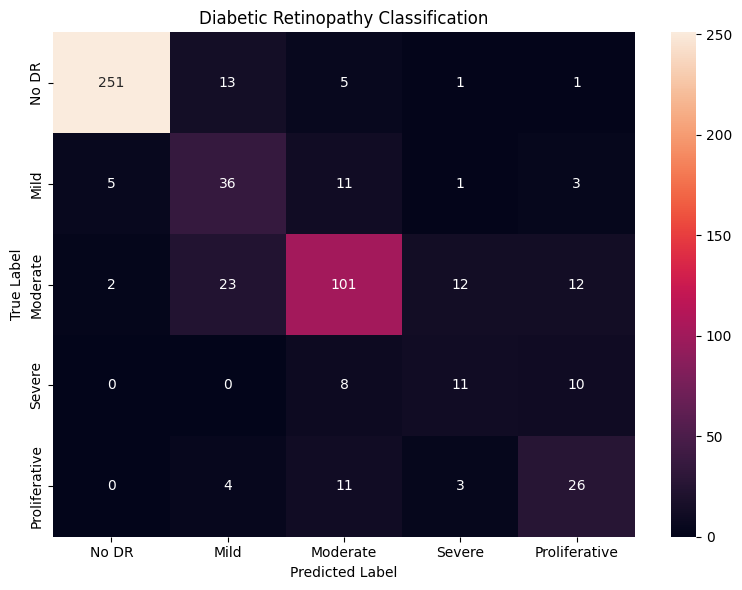

In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Diabetic Retinopathy Classification")

plt.tight_layout()
plt.show()

In [41]:
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_probs.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probs)
    )

In [42]:
from sklearn.metrics import roc_auc_score

y_true, y_probs = get_predictions(
    model,
    test_loader
)

weighted_auc = roc_auc_score(
    y_true,
    y_probs,
    multi_class="ovr",
    average="weighted"
)

print("Weighted Multiclass AUROC:", weighted_auc)

Weighted Multiclass AUROC: 0.9468950960855644


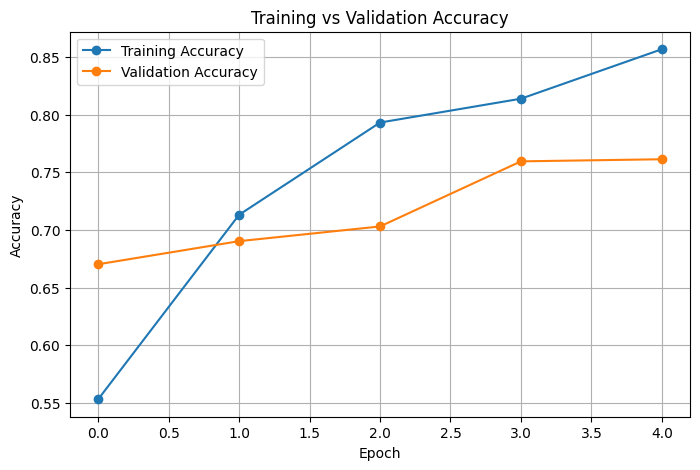

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

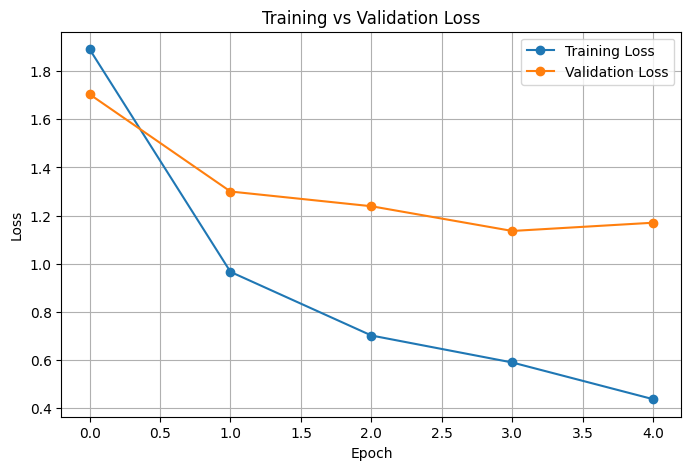

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()